In [2]:
import pandas as pd
books = pd.read_csv("../data/books.csv")
ratings = pd.read_csv("../data/ratings.csv")
print(books.shape, ratings.shape)

(10000, 23) (981756, 3)


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")
os.makedirs("../images", exist_ok=True)
print("Libraries loaded")

Libraries loaded


In [3]:
#cell2
books = pd.read_csv("../data/books.csv")
ratings = pd.read_csv("../data/ratings.csv")
tags = pd.read_csv("../data/tags.csv")
book_tags = pd.read_csv("../data/book_tags.csv")

# Find which column in books.csv matches the book_id in ratings.csv
candidates = ["book_id"] + [c for c in books.columns if c != "book_id"]
best_col, best_match = None, -1
for c in candidates:
    if c in books.columns and pd.api.types.is_numeric_dtype(books[c]):
        m = books[c].isin(ratings["book_id"]).sum()
        if m > best_match:
            best_col, best_match = c, m

print("Best matching ID column:", best_col, "| matches:", best_match)

if best_match == 0:
    print("WARNING: no column matches the ratings book_id")
elif best_col != "book_id":
    books = books.drop(columns=["book_id"], errors="ignore").rename(columns={best_col: "book_id"})
    print(f"Renamed '{best_col}' -> 'book_id'")

print("Books:", books.shape, "| Ratings:", ratings.shape)
books.head()

Best matching ID column: id | matches: 10000
Renamed 'id' -> 'book_id'
Books: (10000, 22) | Ratings: (981756, 3)


,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,Harry Potter and the Sorcerer's Stone (Harry P...,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,"Twilight (Twilight, #1)",...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


In [ ]:
print(" Missing values (books) ")
print(books.isnull().sum()[books.isnull().sum() > 0])

print("\n Missing values (ratings)")
print(ratings.isnull().sum())

print("\n Duplicate ratings (same user, same book) ")
print(ratings.duplicated(subset=["user_id", "book_id"]).sum())

print("\n Rating value range ")
print(ratings["rating"].min(), "to", ratings["rating"].max())

=== Missing values (books) ===
isbn                          700
isbn13                        585
original_publication_year      21
original_title                585
language_code                1084
dtype: int64

=== Missing values (ratings) ===
book_id    0
user_id    0
rating     0
dtype: int64

=== Duplicate ratings (same user, same book) ===
2278

=== Rating value range ===
1 to 5


In [4]:
#cell4
# 1. Remove duplicate ratings
ratings = ratings.drop_duplicates(subset=["user_id", "book_id"])

# 2. Remove invalid ratings (outside 1-5)
ratings = ratings[(ratings["rating"] >= 1) & (ratings["rating"] <= 5)]

# 3. Keep only the useful book columns that exist in the file
wanted_cols = ["book_id", "goodreads_book_id", "title", "authors",
               "original_publication_year", "average_rating",
               "ratings_count", "language_code", "image_url"]
available_cols = [c for c in wanted_cols if c in books.columns]
missing_cols = [c for c in wanted_cols if c not in books.columns]

books = books[available_cols].copy()
print("Kept columns:", available_cols)
print("Not found in file:", missing_cols)

# 4. Fill missing values
if "title" in books.columns:
    books["title"] = books["title"].fillna("Unknown")
if "authors" in books.columns:
    books["authors"] = books["authors"].fillna("Unknown")
if "original_publication_year" in books.columns:
    books["original_publication_year"] = books["original_publication_year"].fillna(
        books["original_publication_year"].median())

print("\nAfter cleaning ratings:", ratings.shape)
print("After cleaning books:", books.shape)

Kept columns: ['book_id', 'title', 'authors', 'original_publication_year', 'average_rating', 'ratings_count', 'language_code', 'image_url']
Not found in file: ['goodreads_book_id']

After cleaning ratings: (979478, 3)
After cleaning books: (10000, 8)


In [43]:
print("books columns:", list(books.columns))
print("book_tags columns:", list(book_tags.columns))
print("ratings columns:", list(ratings.columns))

books columns: ['book_id', 'title', 'authors', 'original_publication_year', 'average_rating', 'ratings_count', 'language_code', 'image_url']
book_tags columns: ['goodreads_book_id', 'tag_id', 'count']
ratings columns: ['book_id', 'user_id', 'rating']


In [5]:
#cell5
# Keep active users (at least 20 ratings) and popular books (at least 50 ratings)
user_counts = ratings["user_id"].value_counts()
book_counts = ratings["book_id"].value_counts()

active_users = user_counts[user_counts >= 20].index
popular_books = book_counts[book_counts >= 50].index

ratings = ratings[ratings["user_id"].isin(active_users) &
                  ratings["book_id"].isin(popular_books)]

# Random sample of 10,000 users (keeps the laptop fast)
np.random.seed(42)
sample_users = np.random.choice(ratings["user_id"].unique(),
                                size=min(10000, ratings["user_id"].nunique()),
                                replace=False)
ratings = ratings[ratings["user_id"].isin(sample_users)]

# Keep only the books that appear in the ratings
books = books[books["book_id"].isin(ratings["book_id"].unique())]

print("Final ratings:", ratings.shape)
print("Final books:", books.shape)
print("Unique users:", ratings["user_id"].nunique())

Final ratings: (493250, 3)
Final books: (9989, 8)
Unique users: 10000


In [45]:
n_users = ratings["user_id"].nunique()
n_books = ratings["book_id"].nunique()
n_ratings = len(ratings)
sparsity = 1 - (n_ratings / (n_users * n_books))

print(f"Users: {n_users}")
print(f"Books: {n_books}")
print(f"Ratings: {n_ratings}")
print(f"Average rating: {ratings['rating'].mean():.2f}")
print(f"Sparsity: {sparsity*100:.2f}%")

Users: 10000
Books: 9989
Ratings: 493250
Average rating: 3.85
Sparsity: 99.51%


C:\Users\Prashant\AppData\Local\Temp\ipykernel_12912\1565849098.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="rating", data=ratings, palette="viridis")


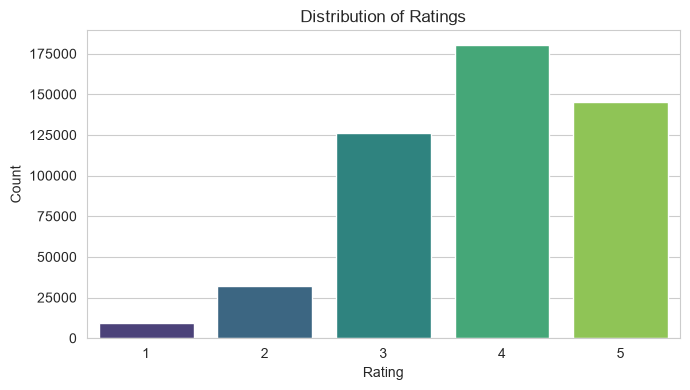

In [10]:
plt.figure(figsize=(7, 4))
sns.countplot(x="rating", data=ratings, palette="viridis")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("../images/01_rating_distribution.png", dpi=150)
plt.show()

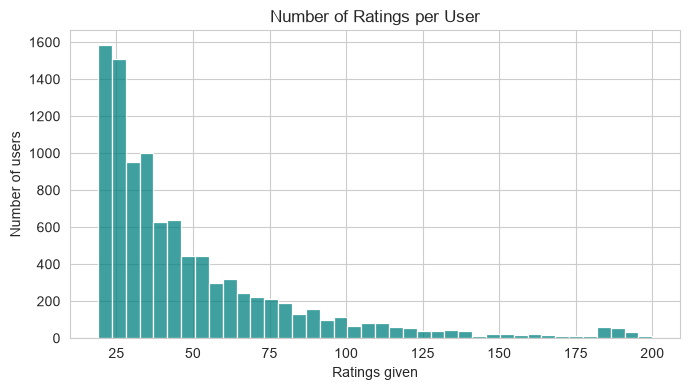

In [46]:
user_activity = ratings.groupby("user_id").size()

plt.figure(figsize=(7, 4))
sns.histplot(user_activity, bins=40, color="teal")
plt.title("Number of Ratings per User")
plt.xlabel("Ratings given")
plt.ylabel("Number of users")
plt.tight_layout()
plt.savefig("../images/02_user_activity.png", dpi=150)
plt.show()

C:\Users\Prashant\AppData\Local\Temp\ipykernel_12912\3616160159.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="count", y="title", data=top_rated_count, palette="rocket")


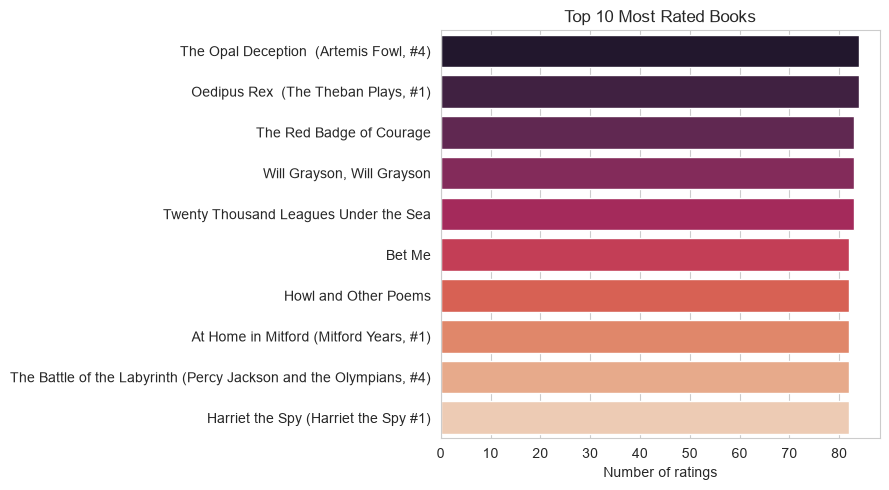

In [54]:
top_rated_count = (ratings.groupby("book_id").size()
                   .sort_values(ascending=False).head(10).reset_index(name="count")
                   .merge(books[["book_id", "title"]], on="book_id"))

plt.figure(figsize=(9, 5))
sns.barplot(x="count", y="title", data=top_rated_count, palette="rocket")
plt.title("Top 10 Most Rated Books")
plt.xlabel("Number of ratings")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../images/03_most_rated_books.png", dpi=150)
plt.show()

Max ratings on a single book: 84


C:\Users\Prashant\AppData\Local\Temp\ipykernel_21220\349047587.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="mean", y="title", data=best_books, palette="mako")


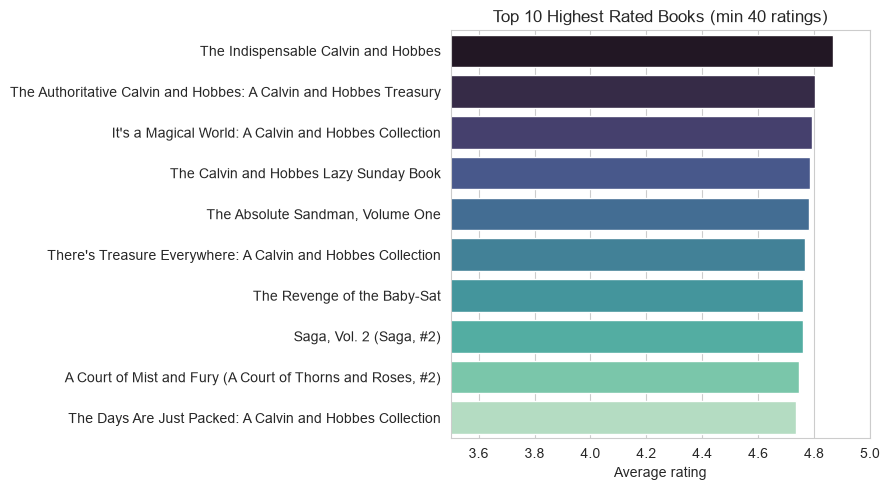

In [6]:
#cell10
book_stats = ratings.groupby("book_id")["rating"].agg(["mean", "count"]).reset_index()
print("Max ratings on a single book:", book_stats["count"].max())

MIN_RATINGS = 40   # threshold chosen to fit the sampled data

best_books = (book_stats[book_stats["count"] >= MIN_RATINGS]
              .sort_values("mean", ascending=False).head(10)
              .merge(books[["book_id", "title"]], on="book_id"))

plt.figure(figsize=(9, 5))
sns.barplot(x="mean", y="title", data=best_books, palette="mako")
plt.xlim(3.5, 5)
plt.title(f"Top 10 Highest Rated Books (min {MIN_RATINGS} ratings)")
plt.xlabel("Average rating")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../images/04_highest_rated_books.png", dpi=150)
plt.show()

C:\Users\Prashant\AppData\Local\Temp\ipykernel_12912\1932641824.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_authors.values, y=top_authors.index, palette="flare")


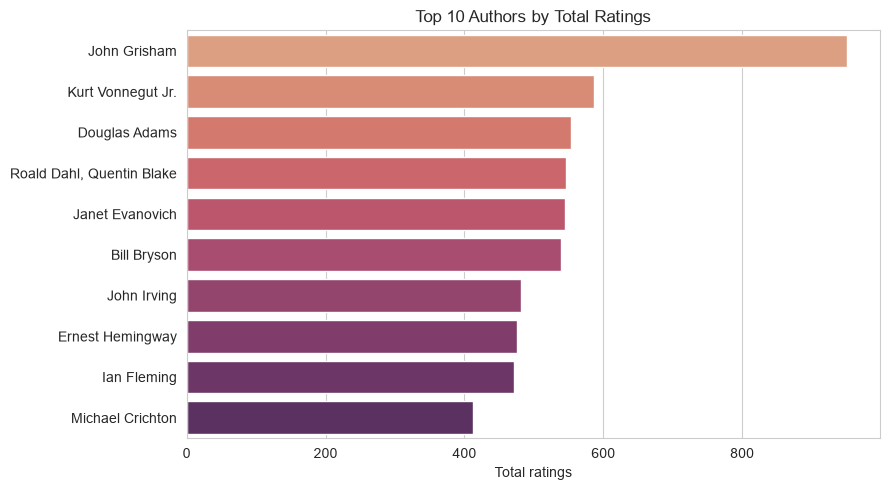

In [35]:
top_authors = (books.merge(ratings.groupby("book_id").size().reset_index(name="n"), on="book_id")
               .groupby("authors")["n"].sum().sort_values(ascending=False).head(10))

plt.figure(figsize=(9, 5))
sns.barplot(x=top_authors.values, y=top_authors.index, palette="flare")
plt.title("Top 10 Authors by Total Ratings")
plt.xlabel("Total ratings")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../images/05_top_authors.png", dpi=150)
plt.show()

In [50]:
ratings.to_csv("../data/ratings_clean.csv", index=False)
books.to_csv("../data/books_clean.csv", index=False)
print("Saved: ratings_clean.csv, books_clean.csv")

Saved: ratings_clean.csv, books_clean.csv


In [52]:
#Diagnosis
books_raw = pd.read_csv("../data/books.csv")
ratings_raw = pd.read_csv("../data/ratings.csv")

print("books columns:", books_raw.columns.tolist())
print("\nbooks head:")
print(books_raw.head(3))
print("\nratings head:")
print(ratings_raw.head(3))
print("\nratings book_id range:", ratings_raw["book_id"].min(), "to", ratings_raw["book_id"].max())

print("\n=== Kon books column ratings er book_id er sathe mele? ===")
for c in books_raw.columns:
    if pd.api.types.is_numeric_dtype(books_raw[c]):
        print(f"{c:30s} -> matching rows: {books_raw[c].isin(ratings_raw['book_id']).sum()}")

print("\nCurrent books shape:", books.shape)
print("Current ratings shape:", ratings.shape)

books columns: ['id', 'book_id', 'best_book_id', 'work_id', 'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year', 'original_title', 'title', 'language_code', 'average_rating', 'ratings_count', 'work_ratings_count', 'work_text_reviews_count', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url']

books head:
   id  book_id  best_book_id  work_id  books_count       isbn        isbn13  \
0   1  2767052       2767052  2792775          272  439023483  9.780439e+12   
1   2        3             3  4640799          491  439554934  9.780440e+12   
2   3    41865         41865  3212258          226  316015849  9.780316e+12   

                       authors  original_publication_year  \
0              Suzanne Collins                     2008.0   
1  J.K. Rowling, Mary GrandPré                     1997.0   
2              Stephenie Meyer                     2005.0   

                             original_title  ... ratings_count  \
0